In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("netflix_titles.csv.zip")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [4]:
# 1. Display the number of rows and columns
print("Dataset Shape:", df.shape)

# 2. Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# 3. Check data types and non-null values
print("\nDataset Information:")
df.info()

# 4. Display statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all").T)

Dataset Shape: (8807, 12)

Column Names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,8807,8807,s1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8807,2,Movie,6131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8807,8807,Dick Johnson Is Dead,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,6173,4528,Rajiv Chilaka,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,7982,7692,David Attenborough,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,7976,748,United States,2818,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8797,1767,"January 1, 2020",109,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,8807.0,NaN,NaN,NaN,2014.180198,8.819312,1925.0,2013.0,2017.0,2019.0,2021.0
rating,8803,17,TV-MA,3207,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,8804,220,1 Season,1793,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Check missing values
print("Missing Values in Each Column:")
print(df.isnull().sum())

# Check duplicate records
print("\nNumber of Duplicate Rows:", df.duplicated().sum())

# Calculate missing-value percentages
missing_percent = (df.isnull().sum() / len(df)) * 100

print("\nMissing Values Percentage:")
display(missing_percent.sort_values(ascending=False))

Missing Values in Each Column:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

Number of Duplicate Rows: 0

Missing Values Percentage:


director        29.908028
country          9.435676
cast             9.367549
date_added       0.113546
rating           0.045418
duration         0.034064
show_id          0.000000
type             0.000000
title            0.000000
release_year     0.000000
listed_in        0.000000
description      0.000000
dtype: float64

In [6]:
# Create a copy so the original dataset remains unchanged
df_clean = df.copy()

# Fill missing categorical values
df_clean["director"] = df_clean["director"].fillna("Unknown")
df_clean["cast"] = df_clean["cast"].fillna("Unknown")
df_clean["country"] = df_clean["country"].fillna("Unknown")
df_clean["rating"] = df_clean["rating"].fillna("Not Rated")

# Remove rows with missing date_added or duration
df_clean = df_clean.dropna(subset=["date_added", "duration"])

# Convert date_added to datetime
df_clean["date_added"] = pd.to_datetime(
    df_clean["date_added"].str.strip(),
    format="mixed",
    errors="coerce"
)

# Check the cleaned dataset
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nRemaining missing values:")
print(df_clean.isnull().sum())

print("\nDuplicate rows:", df_clean.duplicated().sum())

Original dataset shape: (8807, 12)
Cleaned dataset shape: (8794, 12)

Remaining missing values:
show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64

Duplicate rows: 0


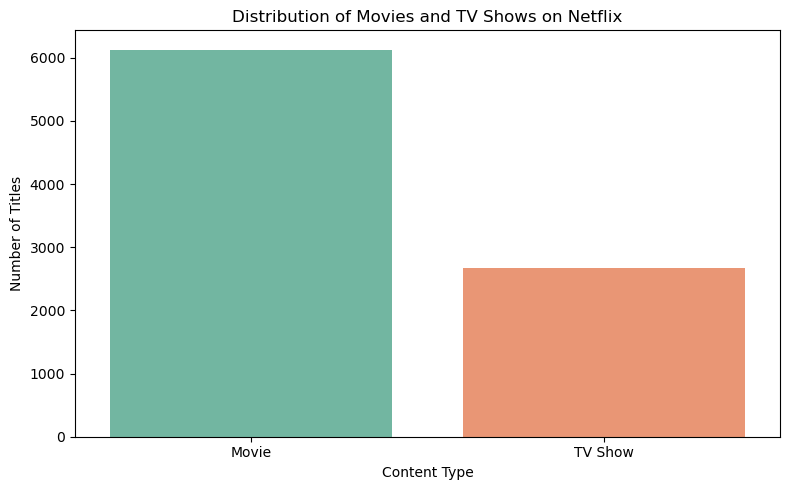

In [7]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="type",
    hue="type",
    legend=False,
    palette="Set2"
)

plt.title("Distribution of Movies and TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()

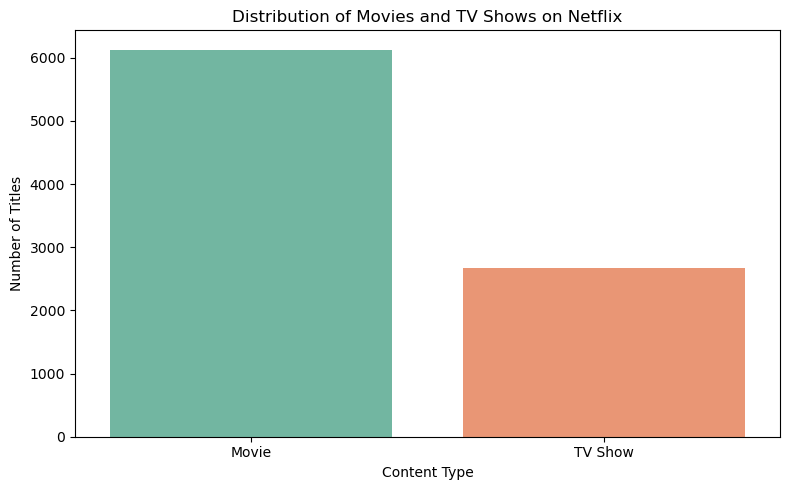


Content Type Counts:
type
Movie      6128
TV Show    2666
Name: count, dtype: int64


In [8]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="type",
    hue="type",
    legend=False,
    palette="Set2"
)

plt.title("Distribution of Movies and TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()

print("\nContent Type Counts:")
print(df_clean["type"].value_counts())

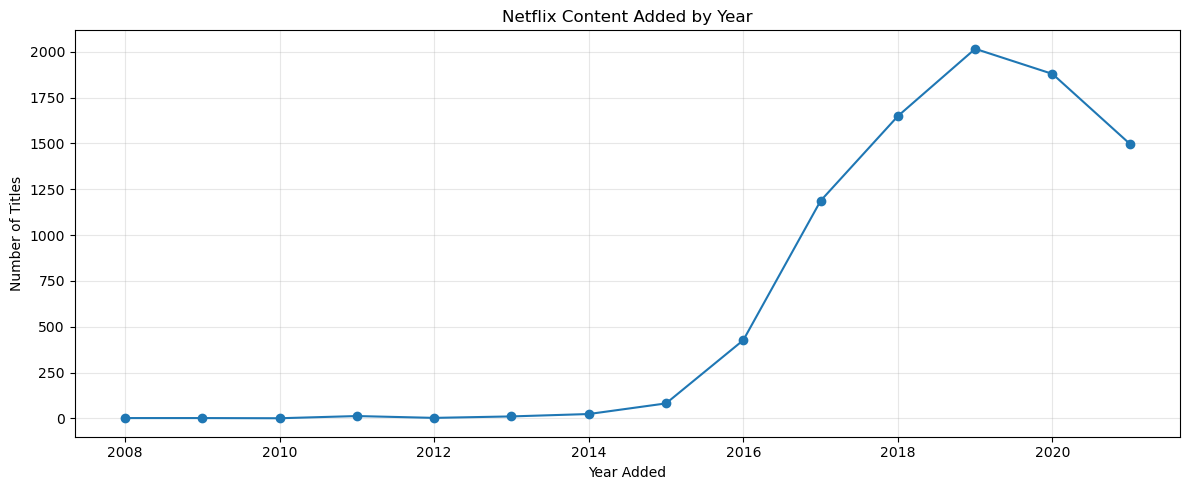

In [9]:
df_clean["year_added"] = df_clean["date_added"].dt.year

yearly_content = df_clean["year_added"].value_counts().sort_index()

plt.figure(figsize=(12, 5))
yearly_content.plot(kind="line", marker="o")

plt.title("Netflix Content Added by Year")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

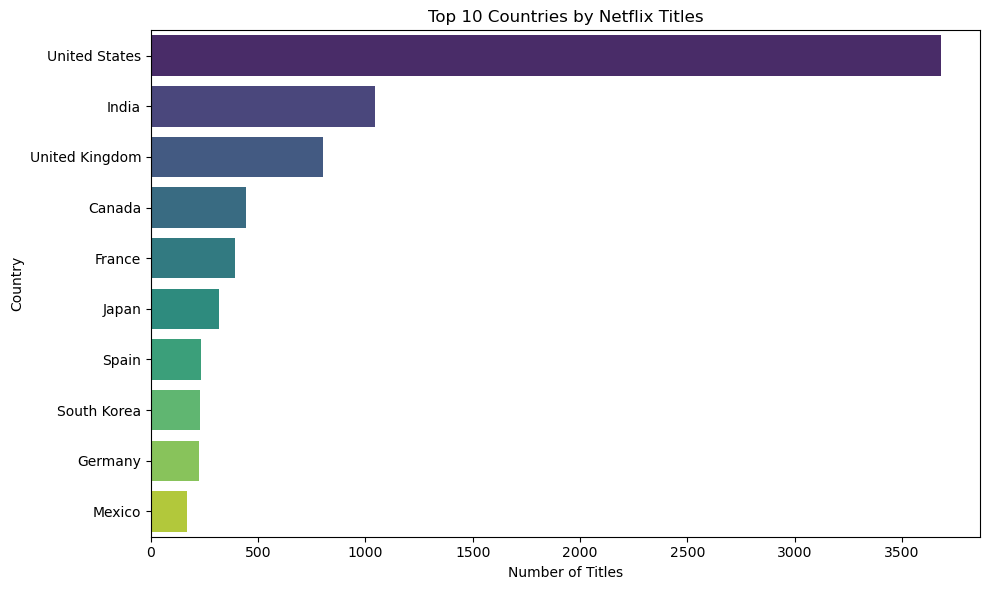

In [10]:
country_data = (
    df_clean[df_clean["country"] != "Unknown"]["country"]
    .str.split(", ")
    .explode()
    .str.strip()
)

top_countries = country_data.value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_countries.values,
    y=top_countries.index,
    hue=top_countries.index,
    legend=False,
    palette="viridis"
)

plt.title("Top 10 Countries by Netflix Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

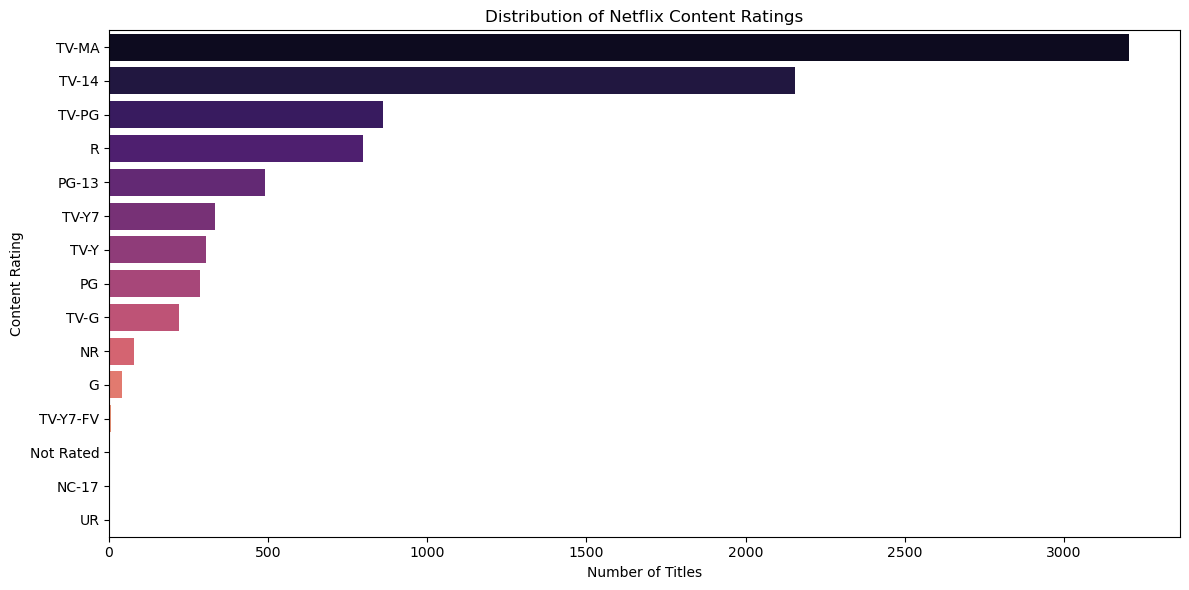

,Number of Titles
rating,
TV-MA,3205
TV-14,2157
TV-PG,861
R,799
PG-13,490
TV-Y7,333
TV-Y,306
PG,287
TV-G,220


In [11]:
plt.figure(figsize=(12, 6))

rating_counts = df_clean["rating"].value_counts()

sns.barplot(
    x=rating_counts.values,
    y=rating_counts.index,
    hue=rating_counts.index,
    legend=False,
    palette="magma"
)

plt.title("Distribution of Netflix Content Ratings")
plt.xlabel("Number of Titles")
plt.ylabel("Content Rating")
plt.tight_layout()
plt.show()

display(rating_counts.to_frame(name="Number of Titles"))

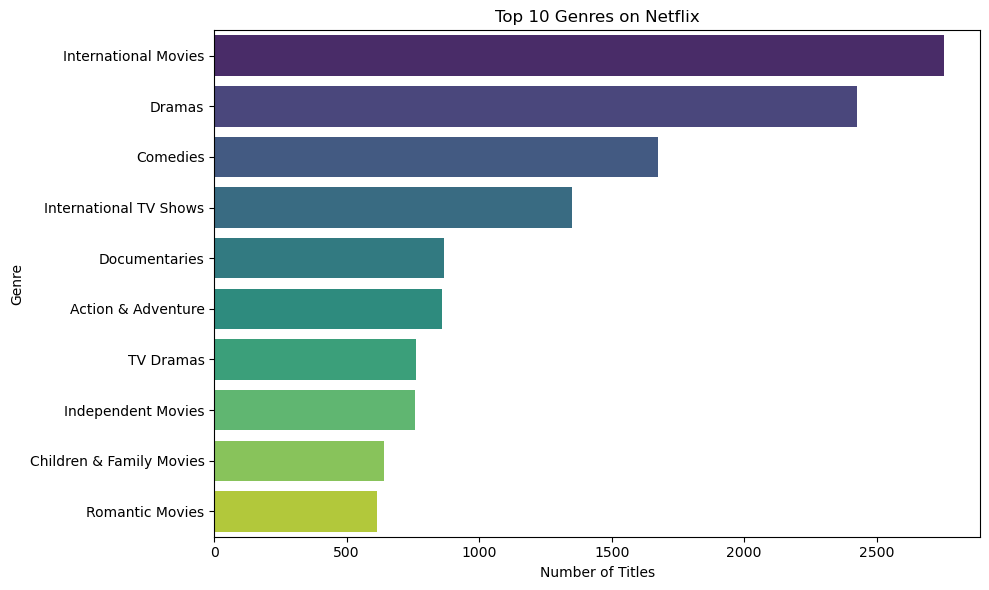

,Number of Titles
listed_in,
International Movies,2752
Dramas,2427
Comedies,1674
International TV Shows,1350
Documentaries,869
Action & Adventure,859
TV Dramas,762
Independent Movies,756
Children & Family Movies,641


In [12]:
genres = (
    df_clean["listed_in"]
    .str.split(", ")
    .explode()
)

top_genres = genres.value_counts().head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index,
    hue=top_genres.index,
    legend=False,
    palette="viridis"
)

plt.title("Top 10 Genres on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

display(top_genres.to_frame(name="Number of Titles"))

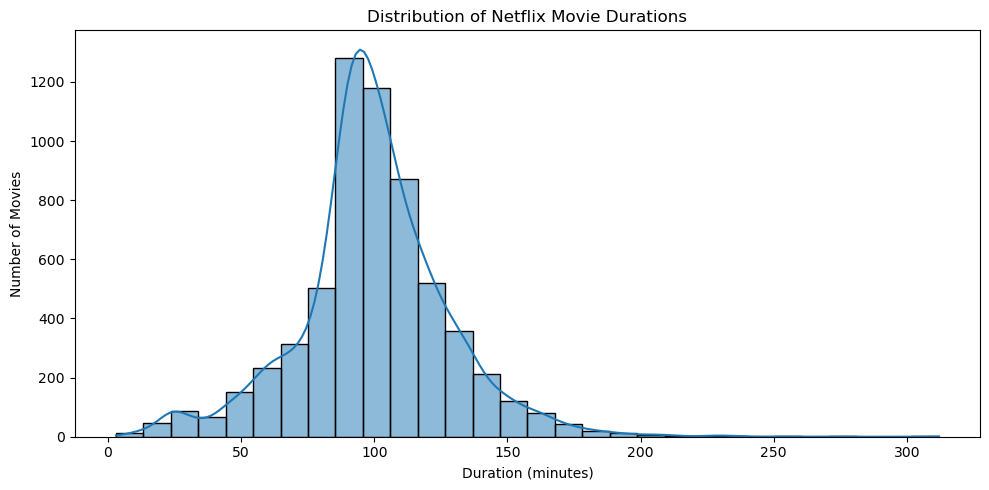

Average movie duration: 99.58 minutes
Median movie duration: 98.0 minutes


In [13]:
movies = df_clean[df_clean["type"] == "Movie"].copy()

movies["duration_minutes"] = (
    movies["duration"]
    .str.extract(r"(\d+)")
    .astype(float)
)

plt.figure(figsize=(10, 5))

sns.histplot(
    movies["duration_minutes"].dropna(),
    bins=30,
    kde=True
)

plt.title("Distribution of Netflix Movie Durations")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

print("Average movie duration:",
      round(movies["duration_minutes"].mean(), 2), "minutes")

print("Median movie duration:",
      movies["duration_minutes"].median(), "minutes")

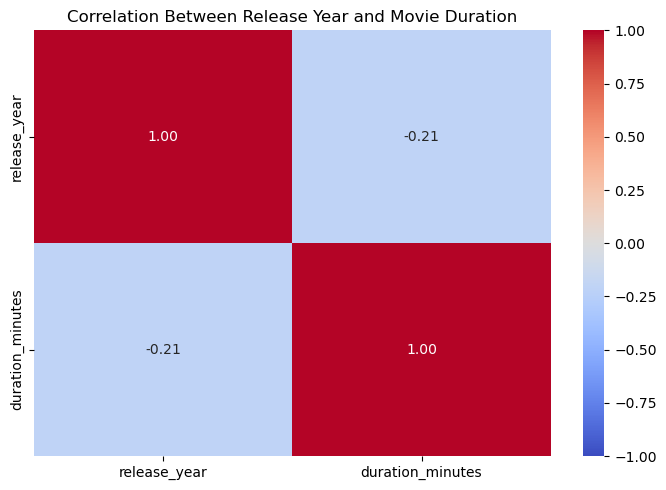

,release_year,duration_minutes
release_year,1.000000,-0.206285
duration_minutes,-0.206285,1.000000


In [14]:
numeric_data = movies[
    ["release_year", "duration_minutes"]
].dropna()

correlation_matrix = numeric_data.corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Release Year and Movie Duration")
plt.tight_layout()
plt.show()

display(correlation_matrix)

In [15]:
# Netflix EDA: Key Findings

content_counts = df_clean["type"].value_counts()
top_rating = df_clean["rating"].value_counts().idxmax()
top_genre = genres.value_counts().idxmax()
top_country = country_data.value_counts().idxmax()

print("=" * 55)
print("       NETFLIX EXPLORATORY DATA ANALYSIS")
print("=" * 55)

print(f"\nTotal titles analyzed: {len(df_clean)}")
print(f"Movies: {content_counts.get('Movie', 0)}")
print(f"TV Shows: {content_counts.get('TV Show', 0)}")
print(f"Most common rating: {top_rating}")
print(f"Most common genre: {top_genre}")
print(f"Top country by title count: {top_country}")

print(
    f"Average movie duration: "
    f"{movies['duration_minutes'].mean():.2f} minutes"
)

print("\nMissing values:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())
print("=" * 55)

       NETFLIX EXPLORATORY DATA ANALYSIS

Total titles analyzed: 8794
Movies: 6128
TV Shows: 2666
Most common rating: TV-MA
Most common genre: International Movies
Top country by title count: United States
Average movie duration: 99.58 minutes

Missing values: 0
Duplicate rows: 0


In [16]:
report = f"""
NETFLIX EXPLORATORY DATA ANALYSIS REPORT
========================================

1. OBJECTIVE
Analyze Netflix titles to identify content patterns,
ratings, genres, countries, and movie durations.

2. DATASET OVERVIEW
Original records: {len(df)}
Records after cleaning: {len(df_clean)}
Columns: {df_clean.shape[1]}
Duplicate records remaining: {df_clean.duplicated().sum()}
Missing values remaining: {df_clean.isnull().sum().sum()}

3. CONTENT DISTRIBUTION
Movies: {content_counts.get('Movie', 0)}
TV Shows: {content_counts.get('TV Show', 0)}

4. KEY FINDINGS
Most common content rating: {top_rating}
Most common genre: {top_genre}
Country with most associated titles: {top_country}
Average movie duration: {movies['duration_minutes'].mean():.2f} minutes

5. CONCLUSION
The analysis explores the composition of Netflix's catalog,
including content types, ratings, genres, geographic distribution,
and movie durations. The visualizations help identify patterns
and support further investigation into the platform's catalog.

Note: Country and genre counts can include multiple entries
for the same title. These results describe the supplied dataset
and do not establish causation or current Netflix availability.
"""

print(report)

with open("Netflix_EDA_Report.txt", "w", encoding="utf-8") as file:
    file.write(report)

print("\nReport saved as Netflix_EDA_Report.txt")


NETFLIX EXPLORATORY DATA ANALYSIS REPORT

1. OBJECTIVE
Analyze Netflix titles to identify content patterns,
ratings, genres, countries, and movie durations.

2. DATASET OVERVIEW
Original records: 8807
Records after cleaning: 8794
Columns: 13
Duplicate records remaining: 0
Missing values remaining: 0

3. CONTENT DISTRIBUTION
Movies: 6128
TV Shows: 2666

4. KEY FINDINGS
Most common content rating: TV-MA
Most common genre: International Movies
Country with most associated titles: United States
Average movie duration: 99.58 minutes

5. CONCLUSION
The analysis explores the composition of Netflix's catalog,
including content types, ratings, genres, geographic distribution,
and movie durations. The visualizations help identify patterns
and support further investigation into the platform's catalog.

Note: Country and genre counts can include multiple entries
for the same title. These results describe the supplied dataset
and do not establish causation or current Netflix availability.


Report

In [17]:
df_clean.to_csv("netflix_cleaned.csv", index=False)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!
